# Classificazione dell'accettabilità delle automobili con Machine Learning e Deep Learning

Elaborato per l'esame di Apprendimento Automatico e Apprendimento Profondo  
Università Telematica San Raffaele Roma

Dataset: [Car Evaluation — UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/19/car+evaluation)  
Linguaggio di programmazione: Python  
Ambiente di sviluppo: Google Colab

## Introduzione

L'obiettivo dell'elaborato è confrontare diversi algoritmi di Machine Learning e Deep Learning per classificare l'accettabilità delle automobili a partire da alcune caratteristiche, tra cui il costo di acquisto, il costo di manutenzione, il numero di posti e il livello di sicurezza.

È stato utilizzato il dataset Car Evaluation del repository UCI, composto da 1.728 combinazioni di caratteristiche associate a quattro classi di accettabilità. Non si tratta di dati raccolti su modelli di auto realmente commercializzati: le classi derivano da un modello di valutazione basato su regole definite.

Dopo l'analisi iniziale del dataset è stata applicata la PCA per studiare la riduzione della dimensionalità. Sono stati poi addestrati tre classificatori tradizionali (Decision Tree, Random Forest e SVM) e una rete neurale artificiale.

Le prestazioni sono state confrontate attraverso Accuracy, Precision, Recall, F1-score e ROC AUC. Le matrici di confusione e le curve ROC consentono di osservare in modo più dettagliato il comportamento dei modelli, soprattutto sulle classi meno rappresentate. È stato inoltre verificato l'effetto della PCA sui classificatori.

# 1. Dataset e analisi iniziale

## 1.1 Ambiente di sviluppo

L'elaborato è stato sviluppato in Python su Google Colab. Per recuperare il dataset direttamente dal repository UCI è stata installata la libreria `ucimlrepo`.

In [ ]:
!pip -q install ucimlrepo

## 1.2 Librerie utilizzate

Per l'organizzazione e l'analisi dei dati è stata utilizzata la libreria `pandas`, mentre i grafici sono stati realizzati con `matplotlib`. Il dataset è stato acquisito attraverso `ucimlrepo`.

La preparazione dei dati, la PCA, i classificatori tradizionali e le metriche di valutazione sono stati gestiti con `scikit-learn`mentre per la rete neurale sono stati utilizzati `TensorFlow` e `Keras`.
Le librerie sono invece importate nelle sezioni in cui vengono utilizzate.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from ucimlrepo import fetch_ucirepo


## 1.3 Caricamento del dataset

Il dataset Car Evaluation è stato caricato dal repository UCI tramite l'identificativo 19. Le sei caratteristiche in ingresso sono state memorizzate nella variabile `X`, mentre le classi da prevedere sono contenute in `y`. Le due parti sono state poi riunite nella tabella `df` per l'analisi iniziale.

Il dataset comprende 1.728 righe e sette colonne: sei caratteristiche e una variabile di classe.

In [ ]:
car = fetch_ucirepo(id=19)

X = car.data.features.copy()  # Le 6 caratteristiche utilizzate come input
y = car.data.targets.copy()   # La risposta corretta: classe dell'auto

df = pd.concat([X, y], axis=1)

print("Dataset caricato correttamente!")
print("Numero di righe e colonne:", df.shape)
print("Nomi delle colonne:", list(df.columns))

Dataset caricato correttamente!
Numero di righe e colonne: (1728, 7)
Nomi delle colonne: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']


## 1.4 Caratteristiche delle automobili

Ogni osservazione è descritta da sei caratteristiche:

- `buying` --> Costo di acquisto
- `maint`  --> Costo di manutenzione
- `doors`  --> Numero di porte
- `persons` --> Numero di persone trasportabili
- `lug_boot` --> Dimensione del bagagliaio
- `safety` --> Livello di sicurezza

La colonna `class` contiene la valutazione di accettabilità. I valori delle caratteristiche sono espressi per categorie, come `low`, `med`, `high` e `vhigh` e non indicano prezzi in euro o informazioni su specifici modelli di auto.
La tabella seguente mostra le prime dieci osservazioni del dataset.

In [ ]:
display(df.head(10))

print("Numero di esempi:", len(df))
print("Numero di feature:", X.shape[1])
print("Nome della variabile target:", y.columns[0])

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
5,vhigh,vhigh,2,2,med,high,unacc
6,vhigh,vhigh,2,2,big,low,unacc
7,vhigh,vhigh,2,2,big,med,unacc
8,vhigh,vhigh,2,2,big,high,unacc
9,vhigh,vhigh,2,4,small,low,unacc


Numero di esempi: 1728
Numero di feature: 6
Nome della variabile target: class


## 1.5 Controllo dei dati

L'analisi iniziale non ha rilevato valori mancanti né righe duplicate dunque non sono quindi state necessarie operazioni di sostituzione dei valori o eliminazione delle osservazioni.

Tutte le colonne sono di tipo `object`, coerentemente con la presenza di valori categorici.

In [ ]:
print("VALORI MANCANTI PER COLONNA")
print(df.isna().sum())

print("\nRighe duplicate:", df.duplicated().sum())
print("\nTIPI DELLE COLONNE")
print(df.dtypes)

VALORI MANCANTI PER COLONNA
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Righe duplicate: 0

TIPI DELLE COLONNE
buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object


## 1.6 Valori possibili delle caratteristiche

Sono state esaminate le categorie disponibili per ciascuna caratteristica. Costo di acquisto, costo di manutenzione e numero di porte hanno quattro possibili valori, mentre numero di persone, dimensione del bagagliaio e sicurezza ne hanno tre.

Diverse categorie seguono un ordine naturale, tuttavia, assegnare direttamente numeri consecutivi introdurrebbe distanze che non sono definite dal dataset. Per questo motivo, nella preparazione dei dati è stato utilizzato il One-Hot Encoding.

In [ ]:
for nome_colonna in X.columns:
    valori = sorted(X[nome_colonna].astype(str).unique())
    print(f"{nome_colonna}: {valori}")

buying: ['high', 'low', 'med', 'vhigh']
maint: ['high', 'low', 'med', 'vhigh']
doors: ['2', '3', '4', '5more']
persons: ['2', '4', 'more']
lug_boot: ['big', 'med', 'small']
safety: ['high', 'low', 'med']


## 1.7 Distribuzione delle classi

La distribuzione delle classi è sbilanciata in quanto su 1.728 esempi, 1.210 appartengono alla classe `unacc` (70,02%), 384 ad `acc` (22,22%), 69 a `good` (3,99%) e 65 a `vgood` (3,76%).

Un classificatore che restituisse sempre `unacc` raggiungerebbe già il 70,02% di Accuracy senza riconoscere nessuna delle altre classi. Per questo motivo, oltre all'Accuracy sono state considerate le metriche macro e le matrici di confusione.

,Numero esempi,Percentuale (%)
class,,
unacc,1210,70.02
acc,384,22.22
good,69,3.99
vgood,65,3.76


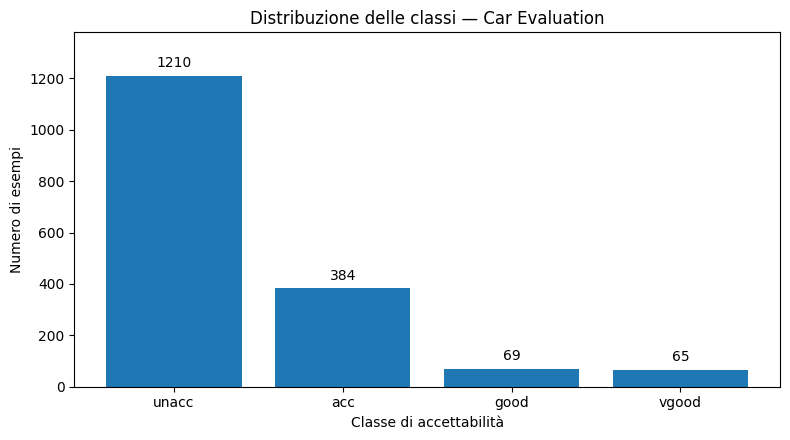

Grafico salvato in: grafici/distribuzione_classi.png


In [ ]:
ordine_classi = ["unacc", "acc", "good", "vgood"]
conteggi = df["class"].value_counts().reindex(ordine_classi, fill_value=0)
percentuali = conteggi / len(df) * 100

riepilogo = pd.DataFrame({
    "Numero esempi": conteggi,
    "Percentuale (%)": percentuali.round(2)
})
display(riepilogo)

cartella_grafici = Path("grafici")
cartella_grafici.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
barre = ax.bar(ordine_classi, conteggi.values)
ax.bar_label(barre, padding=4)
ax.set_title("Distribuzione delle classi — Car Evaluation")
ax.set_xlabel("Classe di accettabilità")
ax.set_ylabel("Numero di esempi")
ax.set_ylim(0, conteggi.max() * 1.14)
plt.tight_layout()
plt.savefig(cartella_grafici / "distribuzione_classi.png", dpi=200, bbox_inches="tight")
plt.show()

print("Grafico salvato in: grafici/distribuzione_classi.png")

# 2. Preparazione dei dati

Per confrontare i modelli in modo corretto è stata mantenuta la stessa suddivisione in training, validation e test. Le trasformazioni necessarie sono state definite sui soli dati di training e applicate successivamente agli altri due gruppi, senza utilizzare informazioni del test durante l'addestramento.


## 2.1 Suddivisione del dataset

Le 1.728 osservazioni sono state divise in 1.036 esempi per il training, 346 per la validation e 346 per il test, pari approssimativamente al 60%, 20% e 20% del totale.

La suddivisione è stratificata, in modo da mantenere proporzioni simili delle quattro classi in ogni gruppo.
Il parametro `random_state=42` rende riproducibile la selezione degli esempi.

Il training è stato utilizzato per addestrare i modelli, la validation per confrontarli e il test per la valutazione finale. La stessa suddivisione è stata mantenuta anche per la rete neurale.

In [ ]:

from sklearn.model_selection import train_test_split

# Prima divisione: 80% sviluppo e 20% test
X_sviluppo, X_test, y_sviluppo, y_test = train_test_split(
    X,
    y["class"],
    test_size=0.20,
    random_state=42,
    stratify=y["class"]
)

# Seconda divisione: training e validation
X_train, X_val, y_train, y_val = train_test_split(
    X_sviluppo,
    y_sviluppo,
    test_size=0.25,
    random_state=42,
    stratify=y_sviluppo
)

print("Automobili per il training:", len(X_train))
print("Automobili per la validation:", len(X_val))
print("Automobili per il test:", len(X_test))

Automobili per il training: 1036
Automobili per la validation: 346
Automobili per il test: 346


## 2.2 Codifica delle variabili

Le caratteristiche categoriche sono state convertite in numeri tramite One-Hot Encoding. Le sei colonne iniziali sono diventate 21 colonne con valori pari a 0 oppure 1.

Il codificatore è stato adattato esclusivamente sui dati di training e applicato, senza essere ricalcolato, ai gruppi di validation e test. Ogni categoria viene rappresentata da una colonna separata, evitando di attribuire distanze numeriche arbitrarie tra i livelli.

In [ ]:

from sklearn.preprocessing import OneHotEncoder

# Definizione del codificatore
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Adattamento del codificatore esclusivamente sul training
X_train_enc = encoder.fit_transform(X_train)

# Applicazione della medesima trasformazione a validation e test
X_val_enc = encoder.transform(X_val)
X_test_enc = encoder.transform(X_test)

# Verifica delle dimensioni delle matrici
print("Caratteristiche originali:", X_train.shape[1])
print("Caratteristiche dopo la codifica:", X_train_enc.shape[1])

print("Training:", X_train_enc.shape)
print("Validation:", X_val_enc.shape)
print("Test:", X_test_enc.shape)

Caratteristiche originali: 6
Caratteristiche dopo la codifica: 21
Training: (1036, 21)
Validation: (346, 21)
Test: (346, 21)


# 3. Analisi PCA

## 3.1 PCA con due componenti

La PCA è stata applicata alle 21 colonne ottenute con il One-Hot Encoding per rappresentare gli esempi su un grafico bidimensionale. L'algoritmo ricerca le direzioni di maggiore variabilità dei dati senza utilizzare le etichette delle classi. Le etichette sono state impiegate soltanto per distinguere i punti nel grafico.

La prima componente spiega l'8,35% della varianza e la seconda l'8,31%, per un totale del 16,66%. Nel grafico le quattro classi si sovrappongono in diverse zone: le prime due componenti conservano infatti soltanto una parte limitata della variabilità complessiva.

Varianza spiegata dalla prima componente: 8.35 %
Varianza spiegata dalla seconda componente: 8.31 %
Varianza totale conservata: 16.66 %


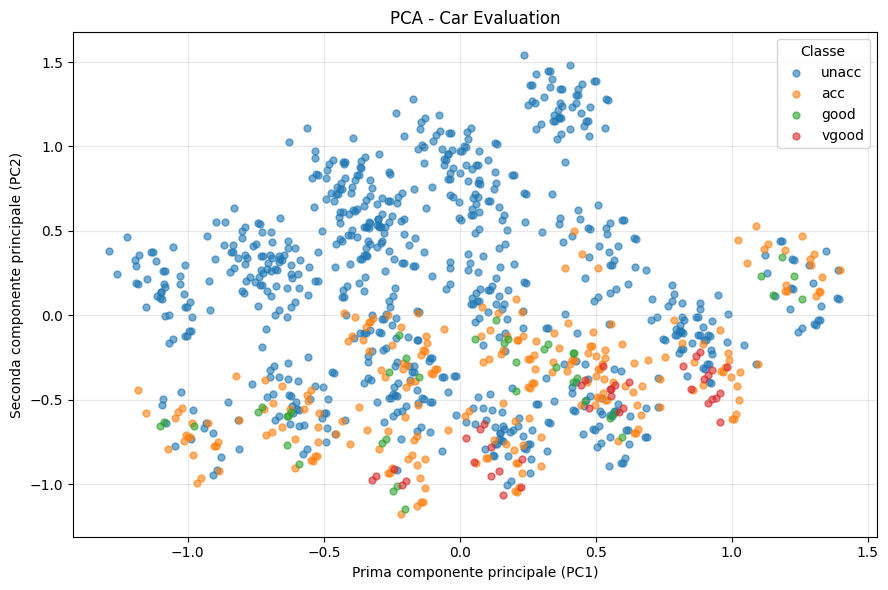

In [ ]:

from sklearn.decomposition import PCA

# PCA bidimensionale per l’analisi esplorativa
pca = PCA(n_components=2)

# Stima delle componenti sul training
X_train_pca = pca.fit_transform(X_train_enc)

# Proiezione coerente dei set non utilizzati nella stima
X_val_pca = pca.transform(X_val_enc)
X_test_pca = pca.transform(X_test_enc)

# Varianza spiegata
varianza = pca.explained_variance_ratio_ * 100

print("Varianza spiegata dalla prima componente:",
      round(varianza[0], 2), "%")

print("Varianza spiegata dalla seconda componente:",
      round(varianza[1], 2), "%")

print("Varianza totale conservata:",
      round(varianza.sum(), 2), "%")

# Grafico
plt.figure(figsize=(9, 6))

for classe in ["unacc", "acc", "good", "vgood"]:
    mask = (y_train == classe).to_numpy()

    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        label=classe,
        alpha=0.6,
        s=25
    )

plt.xlabel("Prima componente principale (PC1)")
plt.ylabel("Seconda componente principale (PC2)")
plt.title("PCA - Car Evaluation")
plt.legend(title="Classe")
plt.grid(alpha=0.3)
plt.tight_layout()

# Salvataggio del grafico
plt.savefig("grafici/pca_automobili.png", dpi=200)

plt.show()

## 3.2 Numero di componenti da conservare

È stata calcolata la varianza spiegata cumulativa, aumentando progressivamente il numero di componenti. Per raggiungere almeno il 90% della varianza sono necessarie 14 componenti, che ne conservano complessivamente il 94,83%.

La varianza spiegata non è una misura dell'accuratezza della classificazione. Una rappresentazione che conserva buona parte della variabilità può comunque perdere informazioni utili a separare le classi. Per questo motivo, i classificatori sono stati confrontati anche utilizzando i dati ridotti tramite PCA.

Componenti necessarie per il 90%: 14
Varianza effettivamente conservata: 94.83 %


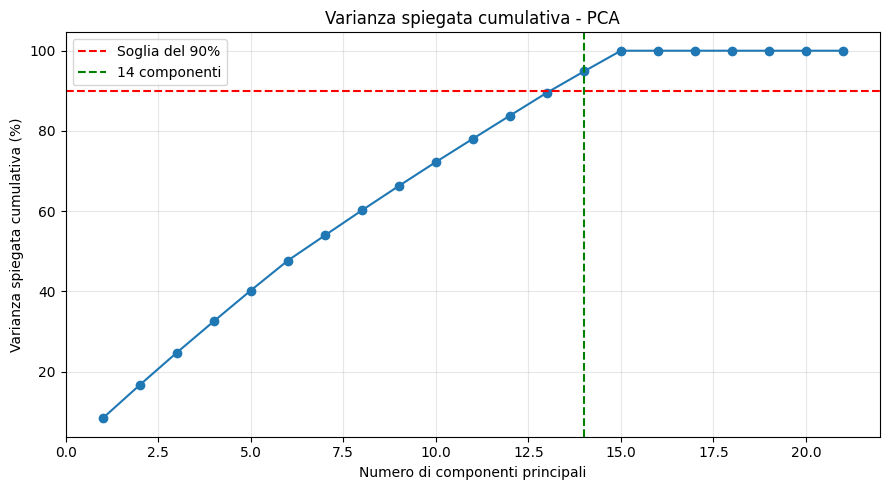

In [ ]:

import numpy as np

# PCA con tutte le componenti disponibili
pca_completa = PCA()

# Stima sul training
pca_completa.fit(X_train_enc)

# Varianza cumulativa
varianza_cumulativa = np.cumsum(
    pca_completa.explained_variance_ratio_
)

# Numero di componenti necessarie
# per raggiungere almeno il 90% della varianza
n_componenti_90 = np.searchsorted(
    varianza_cumulativa, 0.90
) + 1

print("Componenti necessarie per il 90%:",
      n_componenti_90)

print("Varianza effettivamente conservata:",
      round(varianza_cumulativa[n_componenti_90 - 1] * 100, 2),
      "%")

# Grafico
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(varianza_cumulativa) + 1),
    varianza_cumulativa * 100,
    marker="o"
)

plt.axhline(
    y=90,
    color="red",
    linestyle="--",
    label="Soglia del 90%"
)

plt.axvline(
    x=n_componenti_90,
    color="green",
    linestyle="--",
    label=f"{n_componenti_90} componenti"
)

plt.xlabel("Numero di componenti principali")
plt.ylabel("Varianza spiegata cumulativa (%)")
plt.title("Varianza spiegata cumulativa - PCA")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafici/varianza_cumulativa_pca.png",
    dpi=200
)

plt.show()

## 3.3 Dataset ridotto tramite PCA

È stata preparata una seconda rappresentazione del dataset con 14 componenti principali, mantenendo la stessa suddivisione in training, validation e test.

Le matrici risultanti hanno dimensioni `(1036, 14)`, `(346, 14)` e `(346, 14)`. Le 21 colonne codificate sono state mantenute per confrontare le prestazioni con e senza riduzione dimensionale.

In [ ]:

# PCA con il numero di componenti individuato prima
pca14 = PCA(n_components=n_componenti_90)

# Stima della PCA sul training
X_train_pca14 = pca14.fit_transform(X_train_enc)

# Applicazione a validation e test
X_val_pca14 = pca14.transform(X_val_enc)
X_test_pca14 = pca14.transform(X_test_enc)

# Dimensioni dei dati
print("Training:", X_train_pca14.shape)
print("Validation:", X_val_pca14.shape)
print("Test:", X_test_pca14.shape)

print(
    "Varianza conservata:",
    round(sum(pca14.explained_variance_ratio_) * 100, 2),
    "%"
)

Training: (1036, 14)
Validation: (346, 14)
Test: (346, 14)
Varianza conservata: 94.83 %


# 4. Modelli di Machine Learning

## 4.1 Decision Tree

Il primo classificatore è un Decision Tree, che assegna una classe attraverso una sequenza di decisioni sulle caratteristiche in ingresso. La profondità massima è stata fissata a cinque livelli, per limitare la complessità dell'albero.

Sulla validation il modello ha ottenuto un'Accuracy dell'83,82%, ma un F1-score macro del 53,19%. Anche Precision macro (52,65%) e Recall macro (54,60%) risultano nettamente inferiori all'Accuracy. Il divario suggerisce maggiori difficoltà nel riconoscimento delle classi meno frequenti.

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Configurazione del Decision Tree
albero = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Addestramento
albero.fit(X_train_enc, y_train)

# Previsioni sulla validation
pred_val_albero = albero.predict(X_val_enc)

# Metriche
accuracy = accuracy_score(y_val, pred_val_albero)

precision = precision_score(
    y_val, pred_val_albero,
    average="macro", zero_division=0
)

recall = recall_score(
    y_val, pred_val_albero,
    average="macro", zero_division=0
)

f1 = f1_score(
    y_val, pred_val_albero,
    average="macro", zero_division=0
)

print("RISULTATI DECISION TREE - VALIDATION")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-score:", round(f1 * 100, 2), "%")

RISULTATI DECISION TREE - VALIDATION
Accuracy: 83.82 %
Precision: 52.65 %
Recall: 54.6 %
F1-score: 53.19 %


## 4.2 Matrice di confusione del Decision Tree

La matrice di confusione conferma la difficoltà sulle classi meno rappresentate. Il modello riconosce correttamente 222 delle 242 automobili `unacc` e 62 delle 77 `acc`, ma nessuna delle 14 automobili `good`. Per la classe `vgood`, le previsioni corrette sono 6 su 13.

Il risultato mostra perché non è sufficiente considerare soltanto l'Accuracy complessiva.


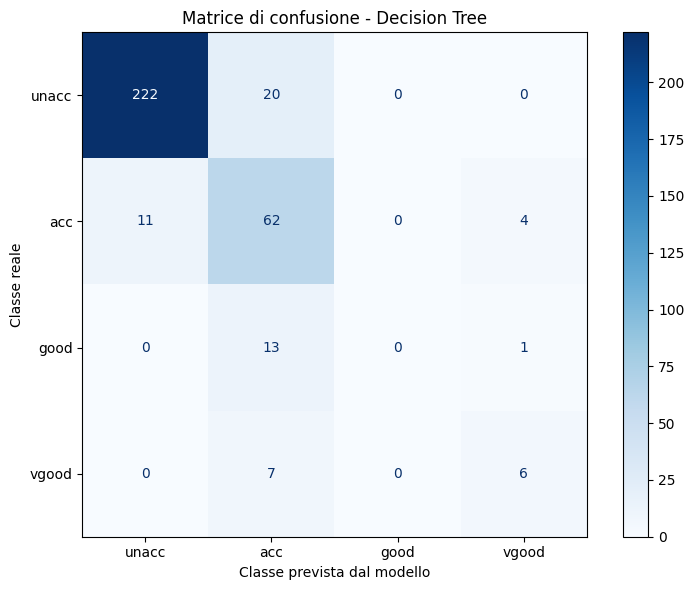

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

# Ordine delle quattro classi
classi = ["unacc", "acc", "good", "vgood"]

# Calcolo della matrice di confusione
matrice = confusion_matrix(
    y_val,
    pred_val_albero,
    labels=classi
)

# Grafico
disp = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=classi
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matrice di confusione - Decision Tree")
plt.xlabel("Classe prevista dal modello")
plt.ylabel("Classe reale")
plt.tight_layout()

# Salvataggio del grafico
Path("grafici").mkdir(exist_ok=True)

plt.savefig(
    "grafici/confusion_matrix_decision_tree.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 4.3 Random Forest

Il secondo classificatore è una Random Forest composta da 200 alberi decisionali. Le previsioni dei diversi alberi vengono combinate per ottenere la classe finale. È stato impostato `class_weight="balanced"` per dare maggiore peso alle classi meno rappresentate durante l'addestramento.

Sulla validation la Random Forest ha raggiunto un'Accuracy del 95,38%, una Precision macro del 91,16%, un Recall macro dell'84,25% e un F1-score macro dell'87,33%. Il miglioramento rispetto al Decision Tree riguarda anche le metriche che tengono conto delle classi meno numerose.

In [ ]:

from sklearn.ensemble import RandomForestClassifier

# Configurazione della Random Forest
foresta = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Addestramento
foresta.fit(X_train_enc, y_train)

# Previsioni sul validation set
pred_val_foresta = foresta.predict(X_val_enc)

# Calcolo delle metriche
accuracy_rf = accuracy_score(y_val, pred_val_foresta)

precision_rf = precision_score(
    y_val, pred_val_foresta,
    average="macro", zero_division=0
)

recall_rf = recall_score(
    y_val, pred_val_foresta,
    average="macro", zero_division=0
)

f1_rf = f1_score(
    y_val, pred_val_foresta,
    average="macro", zero_division=0
)

print("RISULTATI RANDOM FOREST - VALIDATION")
print("Accuracy:", round(accuracy_rf * 100, 2), "%")
print("Precision:", round(precision_rf * 100, 2), "%")
print("Recall:", round(recall_rf * 100, 2), "%")
print("F1-score:", round(f1_rf * 100, 2), "%")

RISULTATI RANDOM FOREST - VALIDATION
Accuracy: 95.38 %
Precision: 91.16 %
Recall: 84.25 %
F1-score: 87.33 %


## 4.4 Matrice di confusione della Random Forest

La Random Forest riconosce correttamente 241 delle 242 automobili `unacc`, 69 delle 77 `acc`, 11 delle 14 `good` e 9 delle 13 `vgood`.

Il confronto con il Decision Tree è particolarmente evidente per le classi `good` e `vgood`, nelle quali le previsioni corrette passano rispettivamente da 0 a 11 e da 6 a 9. Il miglioramento riguarda quindi anche la capacità di riconoscere le categorie meno rappresentate.


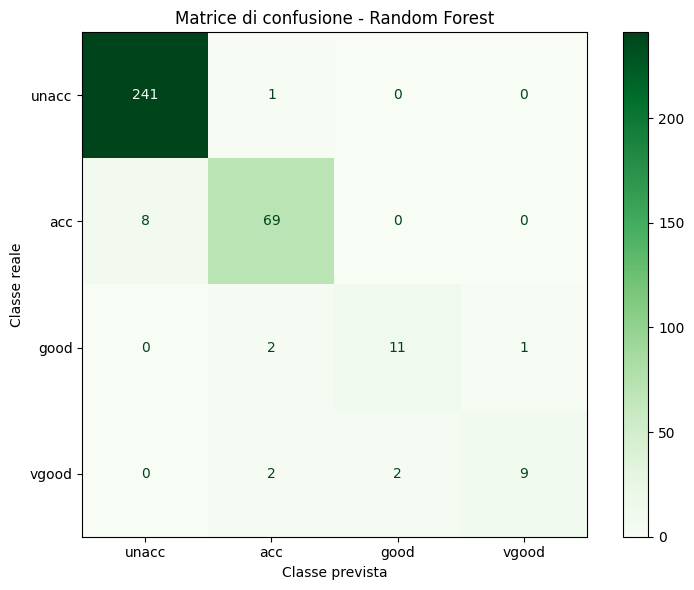

REPORT DI CLASSIFICAZIONE - RANDOM FOREST
              precision    recall  f1-score   support

       unacc       0.97      1.00      0.98       242
         acc       0.93      0.90      0.91        77
        good       0.85      0.79      0.81        14
       vgood       0.90      0.69      0.78        13

    accuracy                           0.95       346
   macro avg       0.91      0.84      0.87       346
weighted avg       0.95      0.95      0.95       346



In [ ]:

from sklearn.metrics import classification_report

# Matrice di confusione della Random Forest
matrice_rf = confusion_matrix(
    y_val,
    pred_val_foresta,
    labels=classi
)

# Grafico
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=matrice_rf,
    display_labels=classi
)

fig, ax = plt.subplots(figsize=(8, 6))

disp_rf.plot(
    cmap="Greens",
    values_format="d",
    ax=ax
)

plt.title("Matrice di confusione - Random Forest")
plt.xlabel("Classe prevista")
plt.ylabel("Classe reale")
plt.tight_layout()

# Salvataggio del grafico
plt.savefig(
    "grafici/confusion_matrix_random_forest.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Metriche per ciascuna classe
print("REPORT DI CLASSIFICAZIONE - RANDOM FOREST")
print(
    classification_report(
        y_val,
        pred_val_foresta,
        labels=classi,
        zero_division=0
    )
)

## 4.5 Support Vector Machine

Come terzo classificatore è stata utilizzata una Support Vector Machine (SVM) con kernel RBF, capace di individuare confini di separazione non lineari. Sono stati impostati `C=3`, `gamma="scale"` e pesi bilanciati per le classi.

La standardizzazione delle caratteristiche è stata inserita nella stessa pipeline della SVM, in modo da ricavare i parametri della trasformazione soltanto dal training.

Sulla validation la SVM ha ottenuto il 97,98% di Accuracy, il 94,94% di Precision macro, il 95,69% di Recall macro e il 95,24% di F1-score macro. Tra i tre classificatori tradizionali è risultata quella con le prestazioni migliori.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Pipeline: prima standardizzazione, poi SVM
modello_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=3,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

# Addestramento
modello_svm.fit(X_train_enc, y_train)

# Previsioni sul validation set
pred_val_svm = modello_svm.predict(X_val_enc)

# Metriche
accuracy_svm = accuracy_score(y_val, pred_val_svm)

precision_svm = precision_score(
    y_val, pred_val_svm,
    average="macro", zero_division=0
)

recall_svm = recall_score(
    y_val, pred_val_svm,
    average="macro", zero_division=0
)

f1_svm = f1_score(
    y_val, pred_val_svm,
    average="macro", zero_division=0
)

print("RISULTATI SVM - VALIDATION")
print("Accuracy:", round(accuracy_svm * 100, 2), "%")
print("Precision:", round(precision_svm * 100, 2), "%")
print("Recall:", round(recall_svm * 100, 2), "%")
print("F1-score:", round(f1_svm * 100, 2), "%")

RISULTATI SVM - VALIDATION
Accuracy: 97.98 %
Precision: 94.94 %
Recall: 95.69 %
F1-score: 95.24 %


## 4.6 Matrice di confusione della SVM

La SVM classifica correttamente 339 automobili su 346. In particolare, riconosce 12 delle 14 automobili `good` e tutte le 13 `vgood`.

Gli errori sono meno numerosi rispetto ai due modelli precedenti e il miglioramento si riflette anche nell'F1-score macro.


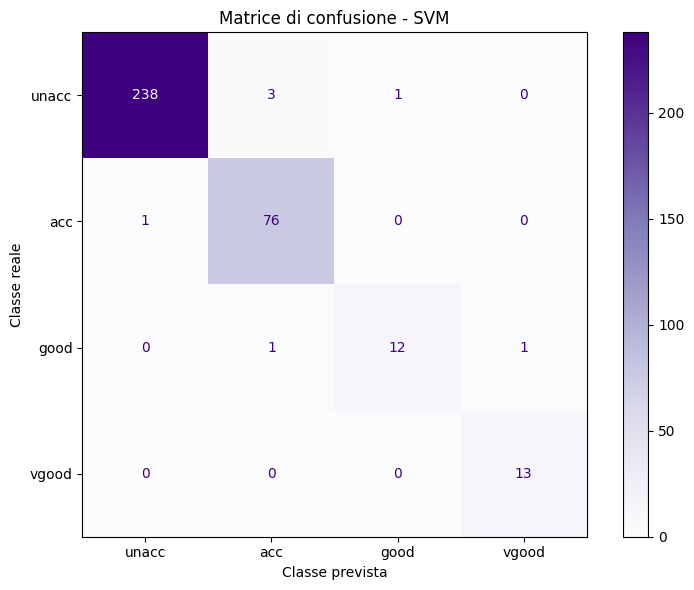

REPORT DI CLASSIFICAZIONE - SVM
              precision    recall  f1-score   support

       unacc       1.00      0.98      0.99       242
         acc       0.95      0.99      0.97        77
        good       0.92      0.86      0.89        14
       vgood       0.93      1.00      0.96        13

    accuracy                           0.98       346
   macro avg       0.95      0.96      0.95       346
weighted avg       0.98      0.98      0.98       346



In [ ]:

# Matrice di confusione della SVM
matrice_svm = confusion_matrix(
    y_val,
    pred_val_svm,
    labels=classi
)

disp_svm = ConfusionMatrixDisplay(
    confusion_matrix=matrice_svm,
    display_labels=classi
)

fig, ax = plt.subplots(figsize=(8, 6))

disp_svm.plot(
    cmap="Purples",
    values_format="d",
    ax=ax
)

plt.title("Matrice di confusione - SVM")
plt.xlabel("Classe prevista")
plt.ylabel("Classe reale")
plt.tight_layout()

plt.savefig(
    "grafici/confusion_matrix_svm.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("REPORT DI CLASSIFICAZIONE - SVM")
print(
    classification_report(
        y_val,
        pred_val_svm,
        labels=classi,
        zero_division=0
    )
)

## 4.7 Confronto dei tre classificatori

Le metriche dei tre classificatori sono state raccolte in un'unica tabella, calcolata sullo stesso validation set. Il Decision Tree presenta le prestazioni più basse, la Random Forest mostra un miglioramento importante e la SVM raggiunge i risultati migliori.

Nella valutazione è stato considerato soprattutto l'F1-score macro, che attribuisce lo stesso peso alle quattro classi anche quando il numero di esempi è molto diverso.


In [ ]:

# Confronto tra i tre algoritmi

modelli = {
    "Decision Tree": pred_val_albero,
    "Random Forest": pred_val_foresta,
    "SVM": pred_val_svm
}

risultati = []

for nome, previsioni in modelli.items():
    risultati.append({
        "Modello": nome,
        "Accuracy (%)": accuracy_score(
            y_val, previsioni
        ) * 100,
        "Precision (%)": precision_score(
            y_val, previsioni,
            average="macro", zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_val, previsioni,
            average="macro", zero_division=0
        ) * 100,
        "F1-score (%)": f1_score(
            y_val, previsioni,
            average="macro", zero_division=0
        ) * 100
    })

confronto = pd.DataFrame(risultati)
confronto = confronto.set_index("Modello")

print("CONFRONTO CLASSIFICATORI - VALIDATION")
display(confronto.round(2))

CONFRONTO CLASSIFICATORI - VALIDATION


,Accuracy (%),Precision (%),Recall (%),F1-score (%)
Modello,,,,
Decision Tree,83.82,52.65,54.60,53.19
Random Forest,95.38,91.16,84.25,87.33
SVM,97.98,94.94,95.69,95.24


## 4.8 ROC AUC

Oltre alle classi previste sono state analizzate le probabilità prodotte dai modelli. Con quattro classi è stato utilizzato l'approccio One-vs-Rest, che confronta ogni classe con l'insieme delle altre tre.

La ROC AUC macro sulla validation è pari a 0,9294 per il Decision Tree, 0,9975 per la Random Forest e 0,9996 per la SVM. Valori vicini a 1 indicano una maggiore capacità di distinguere le classi. Le curve ROC mostrano come cambiano i tassi di veri e falsi positivi al variare della soglia decisionale.


ROC AUC MULTICLASSE - VALIDATION
Decision Tree : 0.9294
Random Forest : 0.9975
SVM : 0.9996


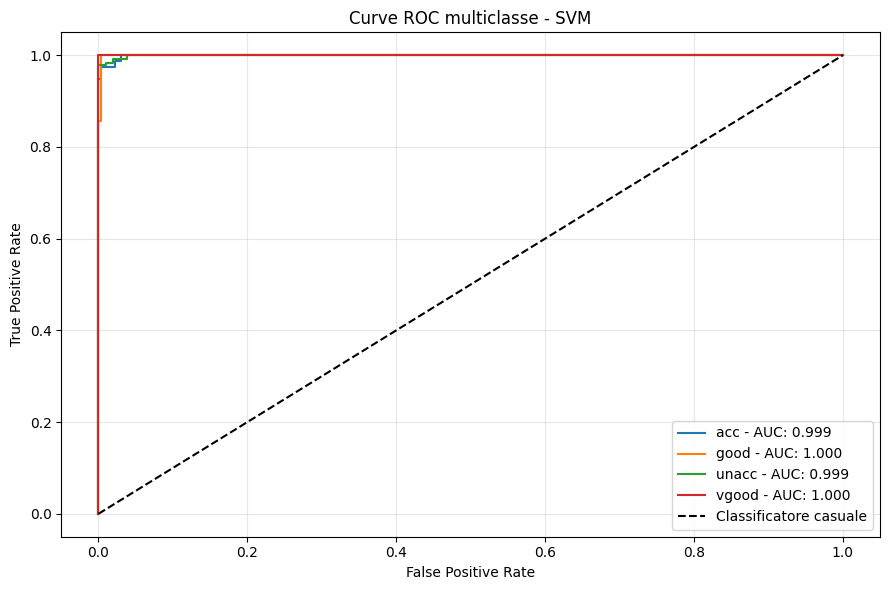

In [ ]:

from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
from pathlib import Path

# Ordine comune delle classi
classi_roc = sorted(y_train.unique())

# I tre classificatori addestrati
modelli_roc = {
    "Decision Tree": albero,
    "Random Forest": foresta,
    "SVM": modello_svm
}

# Calcolo della ROC AUC macro per ogni modello
print("ROC AUC MULTICLASSE - VALIDATION")

for nome, modello in modelli_roc.items():

    probabilita = modello.predict_proba(X_val_enc)

    # Allineamento delle colonne all'ordine delle classi
    indici = [
        list(modello.classes_).index(c)
        for c in classi_roc
    ]

    probabilita = probabilita[:, indici]

    valore_auc = roc_auc_score(
        y_val,
        probabilita,
        labels=classi_roc,
        multi_class="ovr",
        average="macro"
    )

    print(nome, ":", round(valore_auc, 4))

# Curve ROC delle quattro classi per la SVM
y_val_bin = label_binarize(
    y_val,
    classes=classi_roc
)

prob_svm = modello_svm.predict_proba(X_val_enc)

indici_svm = [
    list(modello_svm.classes_).index(c)
    for c in classi_roc
]

prob_svm = prob_svm[:, indici_svm]

plt.figure(figsize=(9, 6))

for i, classe in enumerate(classi_roc):

    fpr, tpr, _ = roc_curve(
        y_val_bin[:, i],
        prob_svm[:, i]
    )

    area = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{classe} - AUC: {area:.3f}"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Classificatore casuale"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curve ROC multiclasse - SVM")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

Path("grafici").mkdir(exist_ok=True)

plt.savefig(
    "grafici/roc_svm.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 4.9 Curve ROC dei modelli ad albero

Sono state generate le curve ROC anche per Decision Tree e Random Forest, oltre a quelle della SVM. Nel caso della Random Forest, le curve si avvicinano all'angolo superiore sinistro del grafico; quelle del Decision Tree risultano più distanti.

Un'AUC elevata non corrisponde necessariamente a zero errori nelle classificazioni finali. Le curve ROC vanno quindi interpretate insieme alle matrici di confusione.


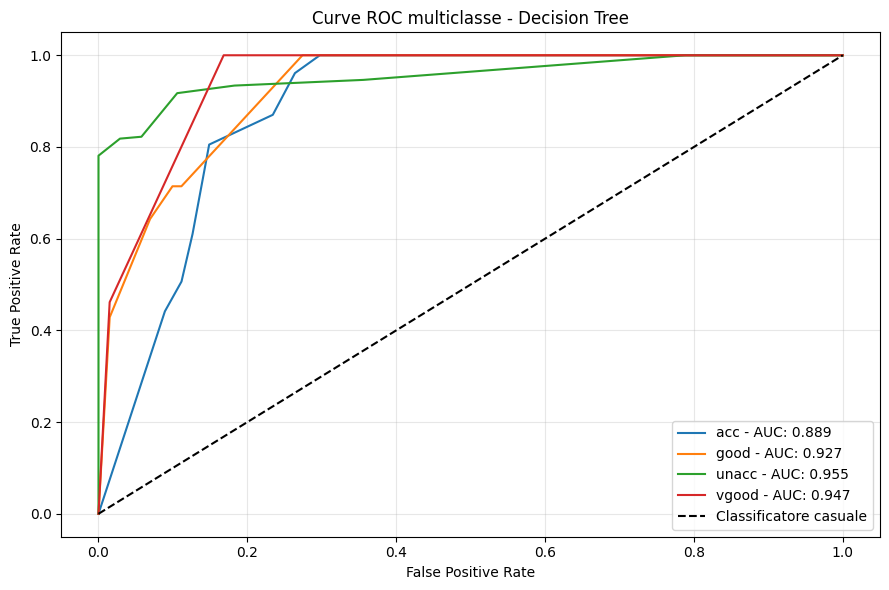

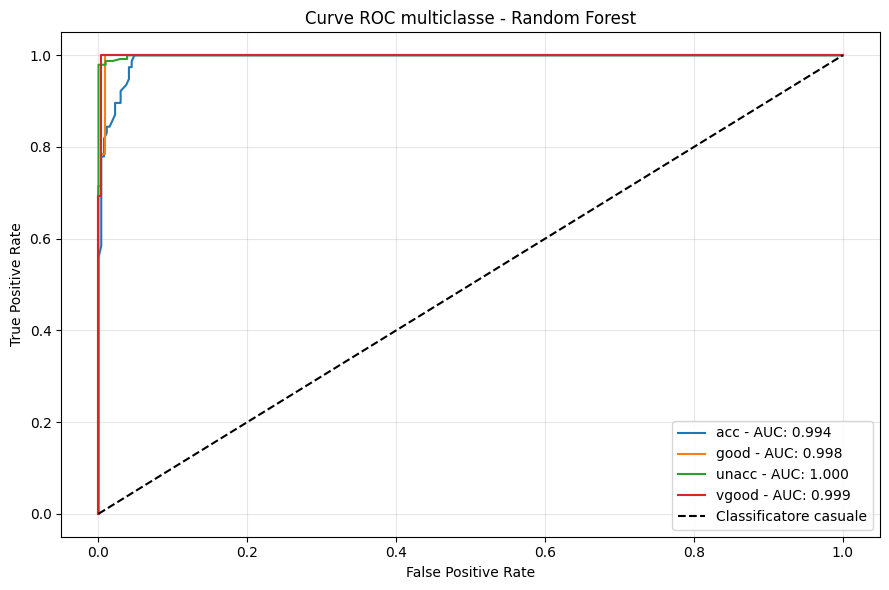

In [ ]:

# Curve ROC per Decision Tree e Random Forest

for nome, modello in [
    ("Decision Tree", albero),
    ("Random Forest", foresta)
]:

    # Probabilità previste
    probabilita = modello.predict_proba(X_val_enc)

    # Ordine delle classi
    indici = [
        list(modello.classes_).index(c)
        for c in classi_roc
    ]

    probabilita = probabilita[:, indici]

    # Grafico
    plt.figure(figsize=(9, 6))

    for i, classe in enumerate(classi_roc):

        fpr, tpr, _ = roc_curve(
            y_val_bin[:, i],
            probabilita[:, i]
        )

        area = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{classe} - AUC: {area:.3f}"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        "k--",
        label="Classificatore casuale"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Curve ROC multiclasse - {nome}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    nome_file = nome.lower().replace(" ", "_")

    plt.savefig(
        f"grafici/roc_{nome_file}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

# 5. Rete neurale

## 5.1 Struttura e addestramento

È stata realizzata una rete neurale MLP con TensorFlow/Keras, utilizzando le stesse 21 caratteristiche codificate e la stessa suddivisione in training, validation e test dei classificatori tradizionali.

La rete comprende due livelli nascosti di 64 e 32 neuroni, entrambi con attivazione ReLU. Dopo il primo livello è stato inserito un Dropout del 20% per limitare il rischio di overfitting. Il livello di uscita contiene quattro neuroni con attivazione Softmax, uno per ciascuna classe.

Per l'addestramento sono stati utilizzati l'ottimizzatore Adam, la funzione di perdita `sparse_categorical_crossentropy`, batch da 32 osservazioni e un massimo di 100 epoche. Sono stati applicati pesi bilanciati alle classi ed è stato previsto l'EarlyStopping in base alla loss sulla validation, con il ripristino dei pesi dell'epoca migliore. Il test è rimasto escluso dall'addestramento e dalla selezione del modello.

In [ ]:

import tensorflow as tf
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

# Impostazione del seme per la riproducibilità
tf.keras.utils.set_random_seed(42)

# Utilizzo degli stessi dati degli altri modelli
X_train_nn = X_train_enc.astype("float32")
X_val_nn = X_val_enc.astype("float32")

# Conversione delle quattro classi in numeri
encoder_y = LabelEncoder()

y_train_nn = encoder_y.fit_transform(y_train)
y_val_nn = encoder_y.transform(y_val)

print("CODIFICA DELLE CLASSI:")
for i, nome in enumerate(encoder_y.classes_):
    print(i, "=", nome)

# Calcolo dei pesi per le classi sbilanciate
pesi = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_nn),
    y=y_train_nn
)

pesi_classi = dict(enumerate(pesi))

# Architettura del classificatore MLP
rete_neurale = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(21,)),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(32, activation="relu"),

    tf.keras.layers.Dense(4, activation="softmax")
])

# Configurazione dell'addestramento
rete_neurale.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Interruzione in caso di mancato miglioramento
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

# Addestramento della rete neurale
storia_nn = rete_neurale.fit(
    X_train_nn,
    y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=100,
    batch_size=32,
    class_weight=pesi_classi,
    callbacks=[early_stopping],
    verbose=1
)

print("\nADDESTRAMENTO COMPLETATO")
print("Epoche eseguite:", len(storia_nn.history["loss"]))

# Struttura della rete
rete_neurale.summary()

CODIFICA DELLE CLASSI:
0 = acc
1 = good
2 = unacc
3 = vgood
Epoch 1/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.4942 - loss: 1.3231 - val_accuracy: 0.7052 - val_loss: 1.1434
Epoch 2/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7297 - loss: 1.1374 - val_accuracy: 0.7659 - val_loss: 0.8839
Epoch 3/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7925 - loss: 0.9504 - val_accuracy: 0.8179 - val_loss: 0.6362
Epoch 4/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8388 - loss: 0.7661 - val_accuracy: 0.8699 - val_loss: 0.4913
Epoch 5/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8716 - loss: 0.6019 - val_accuracy: 0.9075 - val_loss: 0.3898
Epoch 6/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8658 - loss: 0.5186 - val_accuracy: 0.8902 - val_loss: 0.3472
Epoch 7/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8890 - loss: 0.4323 - val_accuracy: 0.8988 - val_loss: 0.3040
Epoch 8/100
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,862 (42.43 KB)

 Trainable params: 3,620 (14.14 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,242 (28.29 KB)

## 5.2 Andamento dell'addestramento

I grafici mostrano l'andamento di Accuracy e Loss durante le epoche, sia sul training sia sulla validation. Il miglioramento è rapido nelle prime epoche e diventa più graduale in seguito.

Nell'esecuzione salvata, la Loss diminuisce in entrambi i gruppi senza un aumento marcato sulla validation. Non emergono quindi segnali evidenti di overfitting. Questo controllo, tuttavia, non è sufficiente da solo a garantire prestazioni equivalenti su dati diversi.

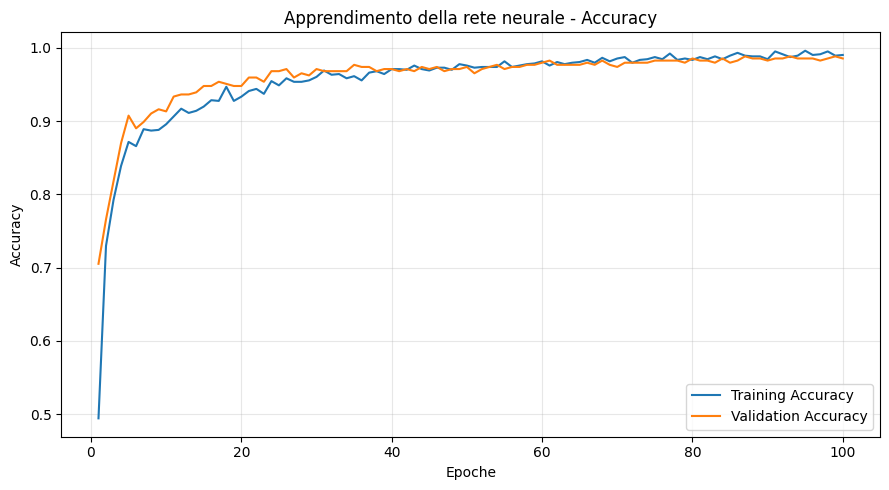

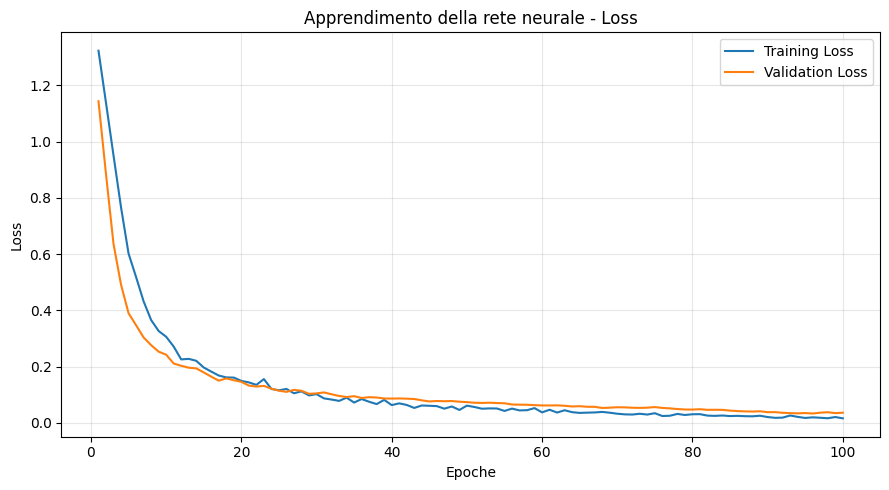

In [ ]:

# Risultati delle epoche
epoche = range(1, len(storia_nn.history["loss"]) + 1)

# Grafico dell'accuratezza
plt.figure(figsize=(9, 5))

plt.plot(
    epoche,
    storia_nn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epoche,
    storia_nn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoche")
plt.ylabel("Accuracy")
plt.title("Apprendimento della rete neurale - Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("grafici/deep_learning_accuracy.png", dpi=200)
plt.show()

# Grafico della perdita (Loss)
plt.figure(figsize=(9, 5))

plt.plot(
    epoche,
    storia_nn.history["loss"],
    label="Training Loss"
)

plt.plot(
    epoche,
    storia_nn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoche")
plt.ylabel("Loss")
plt.title("Apprendimento della rete neurale - Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("grafici/deep_learning_loss.png", dpi=200)
plt.show()

## 5.3 Risultati della rete sulla validation

La classe prevista è stata ricavata selezionando la probabilità Softmax più alta. Sulle 346 automobili di validation la rete ha ottenuto un'Accuracy del 98,55%, valori del 97,36% per Precision, Recall e F1-score macro e una ROC AUC macro di 0,9996.

Il risultato è leggermente superiore a quello della SVM, ma la differenza in Accuracy corrisponde soltanto a due classificazioni corrette in più.


In [ ]:

# Probabilità previste dalla rete neurale
prob_val_nn = rete_neurale.predict(
    X_val_nn,
    verbose=0
)

# Classe con probabilità maggiore
indici_val_nn = np.argmax(prob_val_nn, axis=1)

# Classi originali
pred_val_nn = encoder_y.inverse_transform(
    indici_val_nn
)

# Metriche
accuracy_nn = accuracy_score(y_val, pred_val_nn)

precision_nn = precision_score(
    y_val, pred_val_nn,
    average="macro", zero_division=0
)

recall_nn = recall_score(
    y_val, pred_val_nn,
    average="macro", zero_division=0
)

f1_nn = f1_score(
    y_val, pred_val_nn,
    average="macro", zero_division=0
)

# Calcolo della ROC AUC multiclasse
auc_nn = roc_auc_score(
    y_val,
    prob_val_nn,
    labels=encoder_y.classes_,
    multi_class="ovr",
    average="macro"
)

print("RISULTATI DEEP LEARNING - VALIDATION")
print("Accuracy:", round(accuracy_nn * 100, 2), "%")
print("Precision:", round(precision_nn * 100, 2), "%")
print("Recall:", round(recall_nn * 100, 2), "%")
print("F1-score:", round(f1_nn * 100, 2), "%")
print("ROC AUC:", round(auc_nn, 4))

print("\nREPORT PER CLASSE")
print(
    classification_report(
        y_val,
        pred_val_nn,
        labels=classi,
        zero_division=0
    )
)

RISULTATI DEEP LEARNING - VALIDATION
Accuracy: 98.55 %
Precision: 97.36 %
Recall: 97.36 %
F1-score: 97.36 %
ROC AUC: 0.9996

REPORT PER CLASSE
              precision    recall  f1-score   support

       unacc       0.99      0.99      0.99       242
         acc       0.97      0.97      0.97        77
        good       0.93      0.93      0.93        14
       vgood       1.00      1.00      1.00        13

    accuracy                           0.99       346
   macro avg       0.97      0.97      0.97       346
weighted avg       0.99      0.99      0.99       346



## 5.4 Matrice di confusione della rete neurale

Sulla validation la rete neurale ha classificato correttamente 341 automobili su 346: 240 casi `unacc` su 242, 75 `acc` su 77, 13 `good` su 14 e tutti i 13 `vgood`.

Le prestazioni sulle classi meno frequenti risultano migliori rispetto a Decision Tree e Random Forest. Anche rispetto alla SVM si osserva un piccolo vantaggio, pur con risultati complessivi molto vicini.


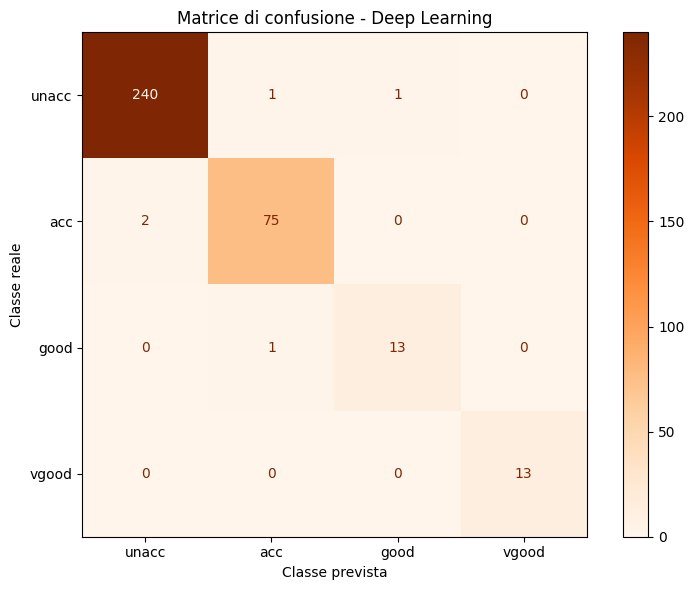

Automobili classificate correttamente: 341
Automobili classificate erroneamente: 5


In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

# Matrice di confusione della rete neurale
matrice_nn = confusion_matrix(
    y_val,
    pred_val_nn,
    labels=classi
)

# Preparazione del grafico
disp_nn = ConfusionMatrixDisplay(
    confusion_matrix=matrice_nn,
    display_labels=classi
)

fig, ax = plt.subplots(figsize=(8, 6))

disp_nn.plot(
    cmap="Oranges",
    values_format="d",
    ax=ax
)

plt.title("Matrice di confusione - Deep Learning")
plt.xlabel("Classe prevista")
plt.ylabel("Classe reale")
plt.tight_layout()

# Salvataggio del grafico
Path("grafici").mkdir(exist_ok=True)

plt.savefig(
    "grafici/confusion_matrix_deep_learning.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Conteggio errori
corrette_nn = (y_val.to_numpy() == pred_val_nn).sum()
errori_nn = len(y_val) - corrette_nn

print("Automobili classificate correttamente:", corrette_nn)
print("Automobili classificate erroneamente:", errori_nn)

## 5.5 Curve ROC della rete neurale

Le curve ROC sono state calcolate per tutte le quattro classi utilizzando le probabilità prodotte dalla rete neurale. L'AUC macro sulla validation è pari a 0,9996.

Le curve risultano molto vicine all'angolo superiore sinistro, indicando una buona capacità discriminante. La matrice di confusione rimane comunque necessaria per individuare gli errori nelle classi previste.


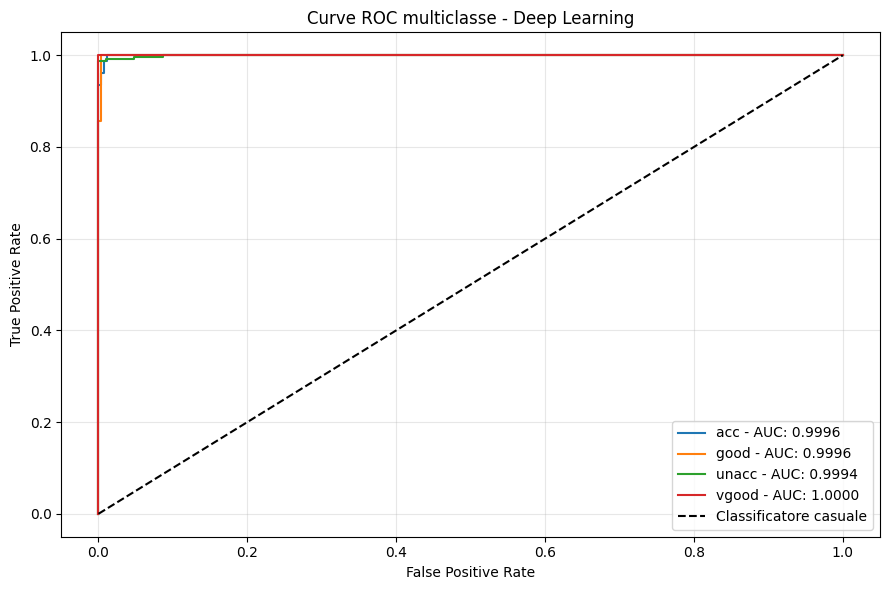

ROC AUC macro Deep Learning: 0.9996


In [ ]:

from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from pathlib import Path

# Ordinamento coerente delle classi
classi_nn = list(encoder_y.classes_)

# Classi reali in formato binario
y_val_bin_nn = label_binarize(
    y_val,
    classes=classi_nn
)

# Grafico ROC
plt.figure(figsize=(9, 6))

for i, classe in enumerate(classi_nn):

    # Curva ROC della classe
    fpr, tpr, soglie = roc_curve(
        y_val_bin_nn[:, i],
        prob_val_nn[:, i]
    )

    # Area sotto la curva
    area = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{classe} - AUC: {area:.4f}"
    )

# Linea di riferimento casuale
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Classificatore casuale"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curve ROC multiclasse - Deep Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Salvataggio del grafico
Path("grafici").mkdir(exist_ok=True)

plt.savefig(
    "grafici/roc_deep_learning.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Calcolo della ROC AUC complessiva
auc_macro_nn = roc_auc_score(
    y_val,
    prob_val_nn,
    labels=classi_nn,
    multi_class="ovr",
    average="macro"
)

print("ROC AUC macro Deep Learning:",
      round(auc_macro_nn, 4))

# 6. Confronto tra i modelli

## 6.1 Risultati sulla validation

Le prestazioni dei quattro modelli sono state confrontate nella stessa tabella usando Accuracy, Precision, Recall, F1-score e ROC AUC. Sulla validation la rete neurale ha ottenuto i risultati migliori per Accuracy (98,55%) e F1-score macro (97,36%), seguita dalla SVM con 97,98% e 95,24%.

In base a questi risultati, prima della valutazione sul test è stata selezionata la rete neurale come modello principale. La SVM rappresenta il confronto più significativo tra i classificatori tradizionali. La differenza tra i due modelli resta comunque contenuta.


CONFRONTO DEI QUATTRO MODELLI - VALIDATION


,Accuracy (%),Precision (%),Recall (%),F1-score (%),ROC AUC macro
Modello,,,,,
Decision Tree,83.82,52.65,54.60,53.19,0.9294
Random Forest,95.38,91.16,84.25,87.33,0.9975
SVM,97.98,94.94,95.69,95.24,0.9996
Rete neurale,98.55,97.36,97.36,97.36,0.9996


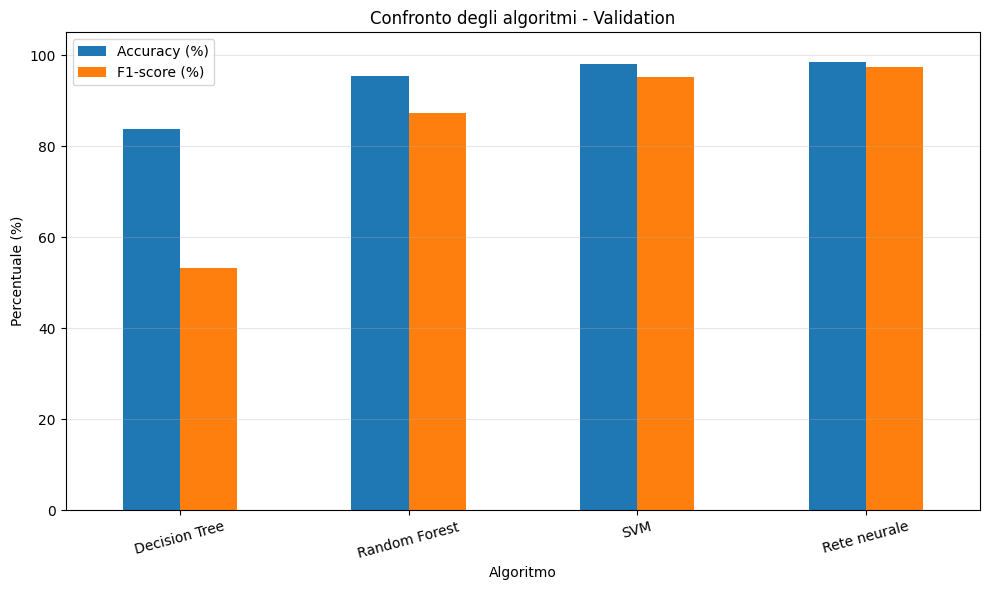

In [ ]:

# Tabella riepilogativa dei quattro modelli
confronto_completo = confronto.copy()

# Risultati rete neurale
confronto_completo.loc["Rete neurale"] = [
    accuracy_nn * 100,
    precision_nn * 100,
    recall_nn * 100,
    f1_nn * 100
]

# Calcolo delle ROC AUC dei tre modelli tradizionali
auc_modelli = {}

for nome, modello in modelli_roc.items():

    probabilita = modello.predict_proba(X_val_enc)

    indici = [
        list(modello.classes_).index(c)
        for c in classi_roc
    ]

    probabilita = probabilita[:, indici]

    auc_modelli[nome] = roc_auc_score(
        y_val,
        probabilita,
        labels=classi_roc,
        multi_class="ovr",
        average="macro"
    )

# ROC AUC rete neurale
auc_modelli["Rete neurale"] = auc_nn

confronto_completo["ROC AUC macro"] = pd.Series(auc_modelli)

print("CONFRONTO DEI QUATTRO MODELLI - VALIDATION")

display(confronto_completo.style.format({
    "Accuracy (%)": "{:.2f}",
    "Precision (%)": "{:.2f}",
    "Recall (%)": "{:.2f}",
    "F1-score (%)": "{:.2f}",
    "ROC AUC macro": "{:.4f}"
}))

# Grafico di confronto
ax = confronto_completo[
    ["Accuracy (%)", "F1-score (%)"]
].plot(kind="bar", figsize=(10, 6))

plt.title("Confronto degli algoritmi - Validation")
plt.xlabel("Algoritmo")
plt.ylabel("Percentuale (%)")
plt.ylim(0, 105)
plt.xticks(rotation=15)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "grafici/confronto_modelli_validation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Risultati in CSV
confronto_completo.to_csv(
    "grafici/confronto_validation.csv"
)

## 6.2 Confronto con e senza PCA

L'addestramento dei tre classificatori tradizionali è stato ripetuto utilizzando le 14 componenti principali al posto delle 21 colonne One-Hot, mantenendo invariati parametri e suddivisione dei dati.

L'F1-score macro è diminuito in tutti e tre i casi: di 3,91 punti percentuali per il Decision Tree, di 27,66 per la Random Forest e di circa 1,91 per la SVM. Conservare il 94,83% della varianza non ha quindi garantito di mantenere tutte le informazioni importanti per la classificazione.

Per la valutazione finale sono stati utilizzati i modelli addestrati sulle 21 colonne codificate, senza riduzione PCA.

In [ ]:

from sklearn.base import clone

# Modelli con parametri invariati
modelli_pca = {
    "Decision Tree": clone(albero),
    "Random Forest": clone(foresta),
    "SVM": clone(modello_svm)
}

risultati_pca = []

# Addestramento sulle componenti PCA
for nome, modello in modelli_pca.items():

    modello.fit(X_train_pca14, y_train)

    # Previsioni sulla validation
    previsioni = modello.predict(X_val_pca14)

    # Probabilità per la ROC AUC
    probabilita = modello.predict_proba(X_val_pca14)

    indici = [
        list(modello.classes_).index(c)
        for c in classi_roc
    ]

    probabilita = probabilita[:, indici]

    # Metriche
    risultati_pca.append({
        "Modello": nome,
        "Accuracy PCA (%)": accuracy_score(
            y_val, previsioni
        ) * 100,
        "F1 PCA (%)": f1_score(
            y_val, previsioni,
            average="macro",
            zero_division=0
        ) * 100,
        "ROC AUC PCA": roc_auc_score(
            y_val,
            probabilita,
            labels=classi_roc,
            multi_class="ovr",
            average="macro"
        )
    })

# Costruzione della tabella
confronto_pca = pd.DataFrame(
    risultati_pca
).set_index("Modello")

# Risultati senza PCA
confronto_pca["Accuracy senza PCA (%)"] = (
    confronto_completo.loc[
        confronto_pca.index, "Accuracy (%)"
    ]
)

confronto_pca["F1 senza PCA (%)"] = (
    confronto_completo.loc[
        confronto_pca.index, "F1-score (%)"
    ]
)

# Differenza tra i due approcci
confronto_pca["Differenza F1 (punti %)"] = (
    confronto_pca["F1 PCA (%)"]
    - confronto_pca["F1 senza PCA (%)"]
)

print("CONFRONTO CON E SENZA PCA - VALIDATION")
display(confronto_pca.round(2))

CONFRONTO CON E SENZA PCA - VALIDATION


,Accuracy PCA (%),F1 PCA (%),ROC AUC PCA,Accuracy senza PCA (%),F1 senza PCA (%),Differenza F1 (punti %)
Modello,,,,,,
Decision Tree,77.46,49.28,0.86,83.82,53.19,-3.91
Random Forest,84.39,59.67,0.97,95.38,87.33,-27.66
SVM,95.09,93.34,1.00,97.98,95.24,-1.91


# 7. Risultati sul test

## 7.1 Valutazione finale

Al termine del confronto sulla validation, i quattro modelli già addestrati sono stati valutati sulle 346 osservazioni del test, senza modificare i parametri in base ai risultati di questo gruppo.

| Modello | Accuracy | Precision macro | Recall macro | F1 macro | ROC AUC macro |
|---|---:|---:|---:|---:|---:|
| Decision Tree | 86,42% | 54,82% | 58,73% | 56,64% | 0,9519 |
| Random Forest | 97,40% | 94,84% | 91,40% | 92,96% | 0,9984 |
| SVM | 98,55% | 98,48% | 99,48% | 98,95% | 0,9999 |
| Rete neurale | 100,00% | 100,00% | 100,00% | 100,00% | 1,0000 |

La rete neurale ha classificato correttamente tutte le 346 osservazioni del test. Il risultato riguarda questo dataset, le cui classi sono definite da regole di valutazione, e non indica una capacità perfetta di giudicare automobili reali.

In [ ]:

# Valutazione finale sul test set indipendente

# Ordine delle classi
classi_test = list(encoder_y.classes_)

# Modelli tradizionali addestrati
modelli_finali = {
    "Decision Tree": albero,
    "Random Forest": foresta,
    "SVM": modello_svm
}

risultati_test = []

# Valutazione dei classificatori tradizionali
for nome, modello in modelli_finali.items():

    predizioni = modello.predict(X_test_enc)
    probabilita = modello.predict_proba(X_test_enc)

    indici = [
        list(modello.classes_).index(c)
        for c in classi_test
    ]

    probabilita = probabilita[:, indici]

    risultati_test.append({
        "Modello": nome,
        "Accuracy (%)": accuracy_score(
            y_test, predizioni
        ) * 100,
        "Precision (%)": precision_score(
            y_test, predizioni,
            average="macro", zero_division=0
        ) * 100,
        "Recall (%)": recall_score(
            y_test, predizioni,
            average="macro", zero_division=0
        ) * 100,
        "F1-score (%)": f1_score(
            y_test, predizioni,
            average="macro", zero_division=0
        ) * 100,
        "ROC AUC": roc_auc_score(
            y_test, probabilita,
            labels=classi_test,
            multi_class="ovr",
            average="macro"
        )
    })

# Valutazione della rete neurale sugli stessi dati
prob_test_nn = rete_neurale.predict(
    X_test_enc.astype("float32"),
    verbose=0
)

pred_test_nn = encoder_y.inverse_transform(
    np.argmax(prob_test_nn, axis=1)
)

risultati_test.append({
    "Modello": "Rete neurale",
    "Accuracy (%)": accuracy_score(
        y_test, pred_test_nn
    ) * 100,
    "Precision (%)": precision_score(
        y_test, pred_test_nn,
        average="macro", zero_division=0
    ) * 100,
    "Recall (%)": recall_score(
        y_test, pred_test_nn,
        average="macro", zero_division=0
    ) * 100,
    "F1-score (%)": f1_score(
        y_test, pred_test_nn,
        average="macro", zero_division=0
    ) * 100,
    "ROC AUC": roc_auc_score(
        y_test, prob_test_nn,
        labels=classi_test,
        multi_class="ovr",
        average="macro"
    )
})

# Costruzione della tabella finale
tabella_test = pd.DataFrame(
    risultati_test
).set_index("Modello")

print("RISULTATI FINALI - TEST SET")
print("Automobili di test:", len(y_test))

display(tabella_test.round(4))

# Salvataggio dei risultati
tabella_test.to_csv("grafici/risultati_finali_test.csv")

RISULTATI FINALI - TEST SET
Automobili di test: 346


,Accuracy (%),Precision (%),Recall (%),F1-score (%),ROC AUC
Modello,,,,,
Decision Tree,86.4162,54.8160,58.7288,56.6425,0.9519
Random Forest,97.3988,94.8379,91.4018,92.9585,0.9984
SVM,98.5549,98.4756,99.4835,98.9529,0.9999
Rete neurale,100.0000,100.0000,100.0000,100.0000,1.0000


## 7.2 Controllo della suddivisione

È stato verificato che gli indici dei tre gruppi non si sovrappongano e che tutte le 1.728 osservazioni siano presenti. È stato inoltre controllato che le caratteristiche e le rispettive etichette risultino allineate.

Tutti i controlli hanno dato esito positivo. Questo conferma l'assenza di righe condivise tra i gruppi, pur non sostituendo la verifica generale delle trasformazioni applicate ai dati.


In [ ]:

# Controllo di integrità della partizione

# Identificativi originali delle osservazioni
indici_train = set(X_train.index)
indici_val = set(X_val.index)
indici_test = set(X_test.index)

# Verifica di eventuali intersezioni
train_val = len(indici_train & indici_val)
train_test = len(indici_train & indici_test)
val_test = len(indici_val & indici_test)

print("CONTROLLO SOVRAPPOSIZIONI")
print("Training / Validation:", train_val)
print("Training / Test:", train_test)
print("Validation / Test:", val_test)

# Copertura del dataset
tutti_indici = indici_train | indici_val | indici_test

print("\nCONTROLLO COMPLETEZZA")
print("Automobili originali:", len(X))
print("Automobili nei tre gruppi:", len(tutti_indici))

# Verifica dell’allineamento tra feature ed etichette
# nei tre sottoinsiemi
allineamento = (
    X_train.index.equals(y_train.index)
    and X_val.index.equals(y_val.index)
    and X_test.index.equals(y_test.index)
)

print("Caratteristiche e classi allineate:", allineamento)

# Esito complessivo
controllo_ok = (
    train_val == 0
    and train_test == 0
    and val_test == 0
    and len(tutti_indici) == len(X)
    and allineamento
)

print("\nCONTROLLO COMPLESSIVO:",
      "SUPERATO" if controllo_ok else "DA VERIFICARE")

CONTROLLO SOVRAPPOSIZIONI
Training / Validation: 0
Training / Test: 0
Validation / Test: 0

CONTROLLO COMPLETEZZA
Automobili originali: 1728
Automobili nei tre gruppi: 1728
Caratteristiche e classi allineate: True

CONTROLLO COMPLESSIVO: SUPERATO


## 7.3 Matrici di confusione sul test

Le matrici di confusione finali mostrano gli errori dei quattro modelli. Il Decision Tree ha classificato correttamente 299 automobili su 346, la Random Forest 337, la SVM 341 e la rete neurale tutte e 346.

La matrice della rete neurale presenta valori soltanto sulla diagonale principale, mentre negli altri modelli rimangono alcuni errori, soprattutto nel Decision Tree.


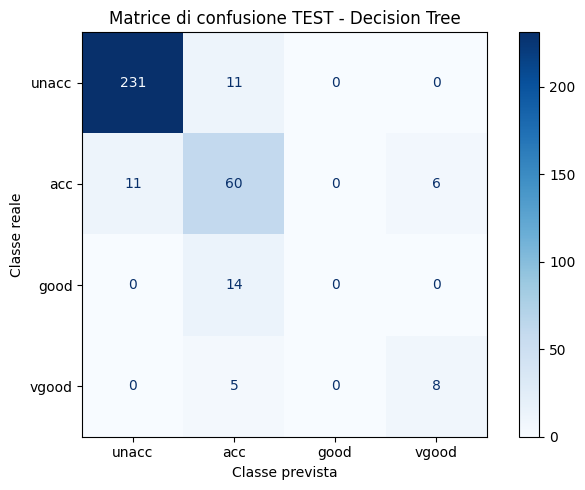

Decision Tree: 299 corrette, 47 errori
---------------------------------------------


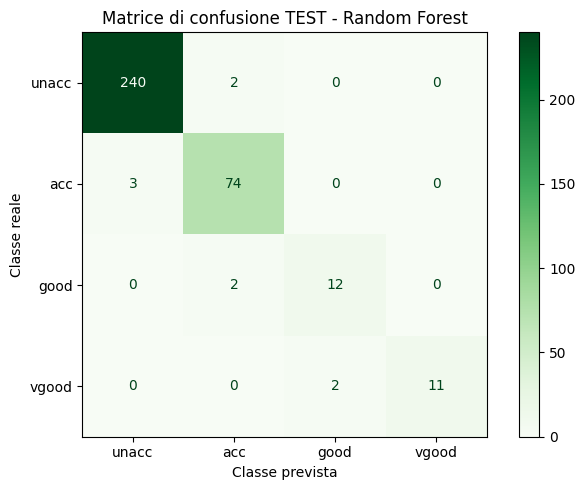

Random Forest: 337 corrette, 9 errori
---------------------------------------------


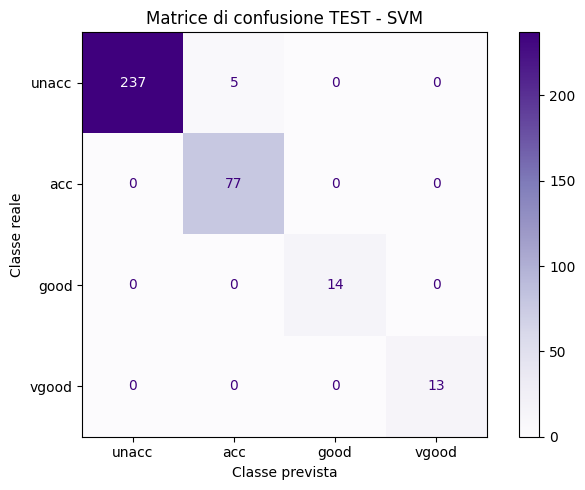

SVM: 341 corrette, 5 errori
---------------------------------------------


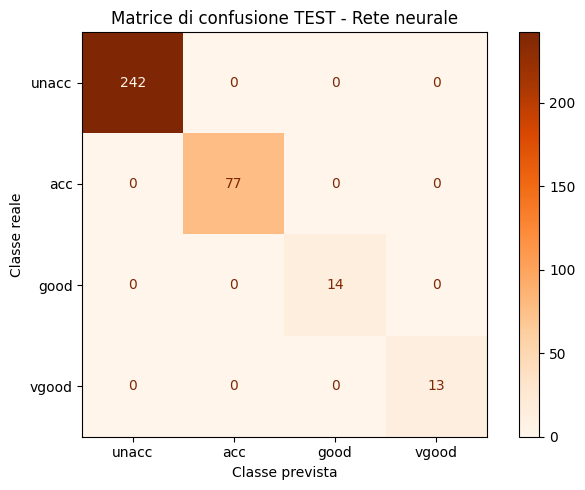

Rete neurale: 346 corrette, 0 errori
---------------------------------------------


In [ ]:

# Matrici di confusione sul test

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

Path("grafici").mkdir(exist_ok=True)

# Previsioni sul test dei modelli preaddestrati
previsioni_finali = {
    "Decision Tree": albero.predict(X_test_enc),
    "Random Forest": foresta.predict(X_test_enc),
    "SVM": modello_svm.predict(X_test_enc),
    "Rete neurale": pred_test_nn
}

colori = ["Blues", "Greens", "Purples", "Oranges"]

# Matrici dei quattro modelli
for (nome, previsioni), colore in zip(
    previsioni_finali.items(), colori
):

    matrice = confusion_matrix(
        y_test,
        previsioni,
        labels=classi
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matrice,
        display_labels=classi
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    disp.plot(
        cmap=colore,
        values_format="d",
        ax=ax
    )

    plt.title(f"Matrice di confusione TEST - {nome}")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe reale")
    plt.tight_layout()

    nome_file = nome.lower().replace(" ", "_")

    plt.savefig(
        f"grafici/test_confusion_{nome_file}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    corrette = (y_test.to_numpy() == previsioni).sum()
    errori = len(y_test) - corrette

    print(f"{nome}: {corrette} corrette, {errori} errori")
    print("-" * 45)

# 8. Conclusioni

Nel confronto sono emerse differenze tra i modelli. Il Decision Tree, con profondità limitata, ha ottenuto le prestazioni più basse, mentre Random Forest e SVM hanno raggiunto risultati migliori. La rete neurale ha presentato le metriche più elevate sulla validation e ha classificato correttamente tutte le 346 osservazioni del test.

Il confronto con la PCA mostra che una riduzione della dimensionalità non comporta necessariamente un miglioramento della classificazione. Pur conservando il 94,83% della varianza con 14 componenti, tutti e tre i classificatori tradizionali hanno ottenuto risultati migliori con le 21 colonne One-Hot. La PCA è stata quindi utile soprattutto per analizzare e visualizzare i dati.

Il principale limite dello studio riguarda il dataset Car Evaluation: gli esempi corrispondono a combinazioni di categorie valutate secondo regole definite, e non a misurazioni raccolte su automobili reali. I risultati non possono quindi essere trasferiti direttamente a situazioni pratiche. Inoltre, le classi `good` e `vgood` contengono pochi esempi e il confronto si basa su una sola suddivisione dei dati.

Una possibile estensione sarebbe ripetere gli esperimenti su più suddivisioni stratificate, oppure utilizzare un dataset basato su osservazioni reali. In questo esperimento è stato comunque possibile verificare che gli algoritmi possono comportarsi in modo diverso sullo stesso problema e che, soprattutto in presenza di classi sbilanciate, è opportuno affiancare all'Accuracy altre metriche di valutazione.

## Riferimenti

- UCI Machine Learning Repository, Car Evaluation: https://archive.ics.uci.edu/dataset/19/car+evaluation
- Documentazione di scikit-learn: https://scikit-learn.org/stable/
- Documentazione di TensorFlow/Keras: https://www.tensorflow.org/guide/keras

I risultati riportati si riferiscono all'esecuzione salvata nel notebook. Eventuali nuove esecuzioni della rete neurale possono produrre valori leggermente diversi in base all'ambiente di calcolo.